# Week 6 - Malaria Detection

**Name:** Zubeda Raheem

**Subject:** Introduction to Applied AI

**Project:** Project 2: Deep Learning Applications

In [ ]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images'
TRAIN_DIR = f'{DATA_ROOT}/cell_images'   # folder with one subfolder per class
TEST_DIR = None                          # no test folder: code carves a grouped test set
GRAYSCALE = False                        # stained blood-cell images are colour
IMG_SIZE = 224
BACKBONE = 'resnet18'                    # or 'resnet50', 'efficientnet_b0'
# Patient id = leading 'C' + digits, e.g. C100P61ThinF_IMG_... -> C100
GROUP_PATTERN = r'^(C\d+)'               # None if no groups
POSITIVE = 'Parasitized'                 # binary tasks: the class you must catch
TARGET_RECALL = 0.95                     # binary tasks: recall you must reach
# ======================================================================

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('Classes found:', sorted(os.listdir(TRAIN_DIR)))

Device: cuda
Classes found: ['Parasitized', 'Uninfected']


In [3]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

# Extra audit lines for the patient-id regex
unmatched = train_df['file'].str.extract(GROUP_PATTERN, expand=False).isna().sum()
print('Files not matching GROUP_PATTERN:', unmatched)
print('Total patients (groups):', train_df.group.nunique())
per_group = train_df.groupby('group')['label'].nunique()
print('Patients with BOTH classes:', (per_group == 2).sum())
print('Patients in Parasitized only:', train_df[train_df.label == 'Parasitized'].group.nunique() - (per_group == 2).sum())
print('Patients in Uninfected only:', train_df[train_df.label == 'Uninfected'].group.nunique() - (per_group == 2).sum())
print(train_df.group.value_counts().head(5).to_string())

label
Parasitized    13779
Uninfected     13779
Imbalance ratio (max / min): 1.0
Images per group: 137.79
Files not matching GROUP_PATTERN: 0
Total patients (groups): 200
Patients with BOTH classes: 150
Patients in Parasitized only: 0
Patients in Uninfected only: 50
group
C68     702
C39     687
C132    639
C99     632
C182    614


         w      h
min   61.0   82.0
50%  130.0  133.0
max  229.0  187.0
Colour modes: {'RGB': 300}


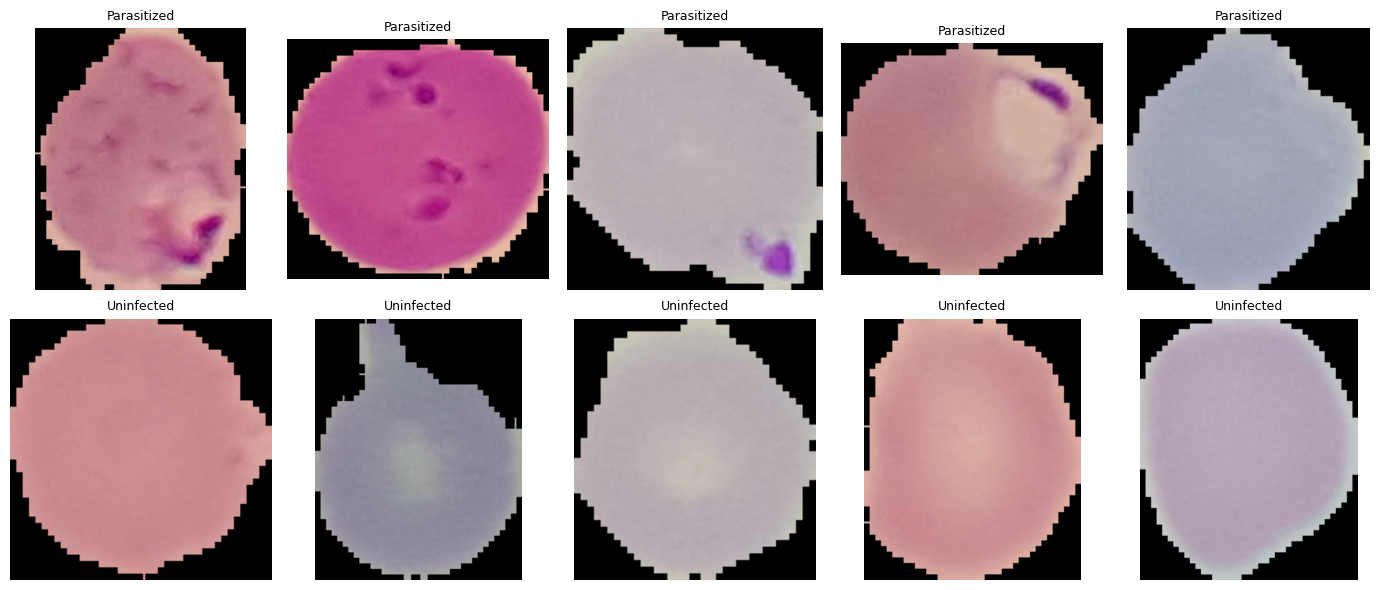

In [4]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Part 1: 27,558 colour images, 2 balanced classes (ratio 1.0), 200 patients

**Numbers:**
- Class counts: Parasitized 13,779 | Uninfected 13,779 | imbalance ratio (max / min) = 1.0
- Image type: all 300 sampled images are RGB. Width: min 61, median 130, max 229 px. Height: min 82, median 133, max 187 px.
- Patient ids: 200 extracted from file names, 0 files unmatched, 137.79 images per patient on average (largest: C68 with 702 images).
- Patient overlap: 150 patients contribute both classes, 50 contribute only Uninfected, 0 contribute only Parasitized.
- Dataset layout: the folder holds a second copy of the data (`cell_images/cell_images`) with the same counts and file names, so I use the inner folder that contains only the two class folders.
- Sample grid (5 images per class): Parasitized cells show dark purple spots, which is the real signal. Uninfected cells look smooth and uniform. The stain colour (pink to blue-grey) and the shape of the black padding vary from slide to slide in both rows, so in these 10 images I cannot see either one separating the classes.

**Decision:** The classes are balanced and every image is RGB at about 130 x 133 pixels, so I keep `GRAYSCALE = False`, resize to 224, and need no imbalance correction. With 138 cells per patient on average, I will split by patient id so that no patient appears on both sides. My first shortcut suspect is the stain colour and black padding, which depend on the slide and staining and not on the parasite. The 50 patients who contribute only Uninfected cells make this a real risk, because a model could learn those patients’ slide look and link it to “Uninfected”. I will test this with Grad-CAM in Part 6.

In [ ]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

t0 = time.time()
train_df['size'] = [os.path.getsize(p) for p in train_df['path']]
print(f'Sizes read in {time.time() - t0:.0f}s', flush=True)

same_size = train_df[train_df.duplicated('size', keep=False)]
print('Files sharing a size with another file:', len(same_size), flush=True)

train_df['md5'] = train_df['path']          # unique placeholder = no duplicate
hashes = []
for i, p in enumerate(same_size['path']):
    hashes.append(md5(p))
    if (i + 1) % 2000 == 0:
        print(f'  hashed {i + 1} / {len(same_size)}  ({time.time() - t0:.0f}s)', flush=True)
train_df.loc[same_size.index, 'md5'] = hashes

dup = train_df[train_df.duplicated('md5', keep=False)]
print('Files that belong to a duplicate set:', len(dup))
print('Duplicate sets:', dup['md5'].nunique())
print('Extra copies (would be removed):', train_df.duplicated('md5').sum())

if len(dup):
    labels_per_set = dup.groupby('md5')['label'].nunique()
    patients_per_set = dup.groupby('md5')['group'].nunique()
    print('Sets with conflicting labels:', (labels_per_set > 1).sum())
    print('Sets spanning more than one patient:', (patients_per_set > 1).sum())

    sets = list(dup.groupby('md5'))[:4]
    fig, axes = plt.subplots(len(sets), 2, figsize=(6, 3 * len(sets)))
    axes = np.atleast_2d(axes)
    for ax_row, (h, g) in zip(axes, sets):
        for ax, (_, r) in zip(ax_row, g.head(2).iterrows()):
            ax.imshow(Image.open(r['path']).convert('RGB'))
            ax.set_title(f"{r['label']}\n{r['file']}", fontsize=7)
            ax.axis('off')
    plt.tight_layout()
    plt.show()

Sizes read in 6s
Files sharing a size with another file: 23699
  hashed 2000 / 23699  (7s)
  hashed 4000 / 23699  (8s)
  hashed 6000 / 23699  (9s)
  hashed 8000 / 23699  (11s)
  hashed 10000 / 23699  (12s)
  hashed 12000 / 23699  (13s)
  hashed 14000 / 23699  (14s)
  hashed 16000 / 23699  (15s)
  hashed 18000 / 23699  (16s)
  hashed 20000 / 23699  (17s)
  hashed 22000 / 23699  (18s)
Files that belong to a duplicate set: 0
Duplicate sets: 0
Extra copies (would be removed): 0


In [ ]:
# Backup so a restart does not cost the 12-minute hashing again
train_df.to_csv('/kaggle/working/train_df_md5.csv', index=False)

# Validation split BY PATIENT: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'], train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if not TEST_DIR:                                   # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Patients per split:', tr_df.group.nunique(), '|',
      va_df.group.nunique(), '|', test_df.group.nunique())
print('Groups shared by train and val :', len(set(tr_df.group) & set(va_df.group)))   # must be 0
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))  # must be 0
print('Groups shared by val and test  :', len(set(va_df.group) & set(test_df.group)))  # must be 0
for name, d in [('train', tr_df), ('val', va_df), ('test', test_df)]:
    print(name, d['label'].value_counts().to_dict())

train 19118 | val 5105 | test 3335
Patients per split: 139 | 33 | 28
Groups shared by train and val : 0
Groups shared by train and test: 0
Groups shared by val and test  : 0
train {'Parasitized': 9586, 'Uninfected': 9532}
val {'Parasitized': 2853, 'Uninfected': 2252}
test {'Uninfected': 1995, 'Parasitized': 1340}


  train: 5000 / 19118 (6s)
  train: 10000 / 19118 (11s)
  train: 15000 / 19118 (17s)
  val: 5000 / 5105 (6s)
test: near-duplicate in train at <0.10: 234 of 3335 | at <0.05: 0 | closest 5: [0.065 0.067 0.068 0.07  0.07 ]
val: near-duplicate in train at <0.10: 249 of 5105 | at <0.05: 0 | closest 5: [0.064 0.069 0.07  0.07  0.072]


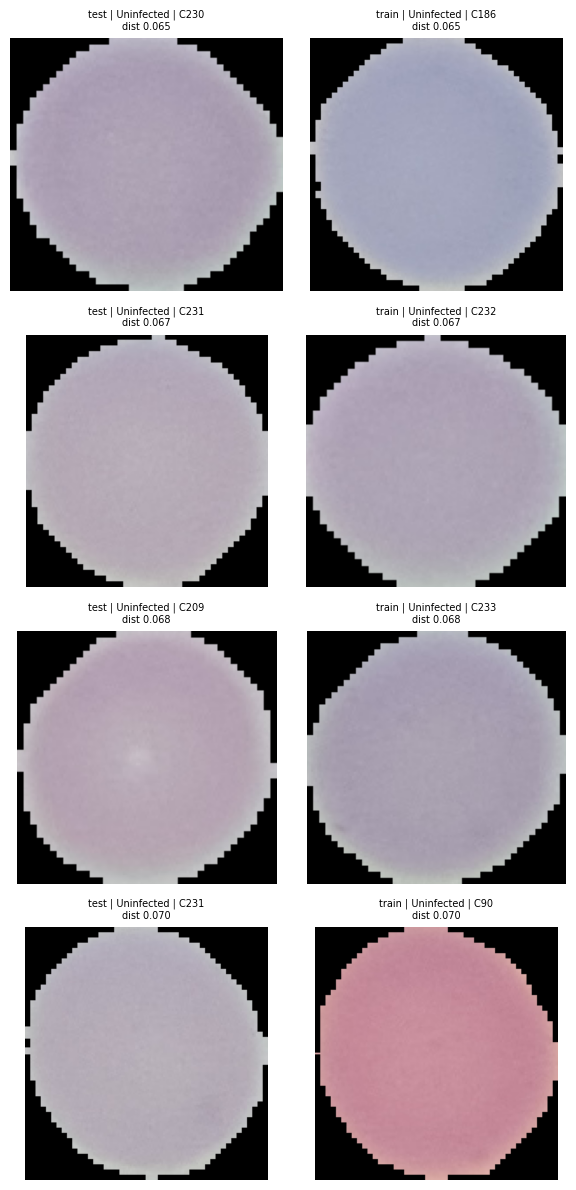

In [ ]:
from concurrent.futures import ThreadPoolExecutor

def fingerprint(path, n=32):
    with Image.open(path) as im:
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

def fingerprints(paths, name):
    t0, out = time.time(), []
    with ThreadPoolExecutor(max_workers=32) as ex:
        for i, f in enumerate(ex.map(fingerprint, paths)):
            out.append(f)
            if (i + 1) % 5000 == 0:
                print(f'  {name}: {i + 1} / {len(paths)} ({time.time() - t0:.0f}s)', flush=True)
    return np.stack(out)

tr_fp = fingerprints(tr_df['path'].tolist(), 'train')
te_fp = fingerprints(test_df['path'].tolist(), 'test')
va_fp = fingerprints(va_df['path'].tolist(), 'val')

def nearest(q, ref):
    d = torch.cdist(torch.tensor(q).to(device), torch.tensor(ref).to(device), p=1) / q.shape[1]
    return d.min(dim=1)

te_d, te_j = nearest(te_fp, tr_fp)
va_d, va_j = nearest(va_fp, tr_fp)
for name, d in [('test', te_d), ('val', va_d)]:
    d = d.cpu().numpy()
    print(f'{name}: near-duplicate in train at <0.10: {(d < 0.10).sum()} of {len(d)}'
          f' | at <0.05: {(d < 0.05).sum()}'
          f' | closest 5: {np.sort(d)[:5].round(3)}')

# Show the 4 closest test-vs-train pairs side by side
order = te_d.argsort()[:4].tolist()
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for row, i in zip(axes, order):
    j = int(te_j[i])
    for ax, r, tag in zip(row, [test_df.iloc[i], tr_df.iloc[j]], ['test', 'train']):
        ax.imshow(Image.open(r['path']).convert('RGB'))
        ax.set_title(f"{tag} | {r['label']} | {r['group']}\ndist {te_d[i]:.3f}", fontsize=7)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Part 2: 0 exact duplicates, 0 near-duplicates at 0.05, and 0 shared patients across 19,118 / 5,105 / 3,335 images

**Numbers:**
- Exact duplicates (file size first, then MD5): I read the byte size of all 27,558 files and hashed only the 23,699 that share a size with another file, since byte-identical files must have the same size. Result: 0 duplicate sets and 0 extra copies, so nothing was removed.
- Near-duplicates (32 x 32 standardized fingerprint, each compared against the train split): at threshold 0.10, 234 of 3,335 test images and 249 of 5,105 validation images were flagged; at threshold 0.05, 0 in both. The closest distances were about 0.065 to 0.072, far above the 0.007 typical of recompressed copies.
- Inspection of the closest pairs: they show different pale, round cells (one pair is pale against clearly pink), so the 0.10 flags are look-alikes, not copies.
- Group split (StratifiedGroupKFold by patient id): train 19,118 images from 139 patients, validation 5,105 from 33, test 3,335 from 28. Groups shared by train and val: 0; train and test: 0; val and test: 0.
- Images per patient: 137.79 on average (27,558 images / 200 patients).
- Label balance by split: train 9,586 Parasitized / 9,532 Uninfected; val 2,853 / 2,252; test 1,340 / 1,995 (40.2% Parasitized).

**Decision:** I found no exact duplicates and no near-duplicates at 0.05, so I removed nothing, and I treat the 0.10 flags as uniform-looking cells because the fingerprint ignores colour. I keep the patient-level split with 0 shared groups, and I will compute the PPV at the test prevalence of 40.2%, since the grouped split could not make the test set 50/50.

**Random split (lab question):** With about 138 cells per patient, a random split would put cells from the same patient and slide on both sides, so the model could recognise a slide's stain and background instead of the parasite. That would raise my test score above what the model would reach on new patients.

In [ ]:
from concurrent.futures import ThreadPoolExecutor

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),      # added: a cell has no left or right
    transforms.RandomVerticalFlip(),        # added: a cell has no up or down
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def load_img(p):
    with Image.open(p) as im:
        return im.convert('L' if GRAYSCALE else 'RGB')   # returns an in-memory copy

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
        t0 = time.time()
        with ThreadPoolExecutor(max_workers=32) as ex:
            self.imgs = list(ex.map(load_img, self.paths))   # preload into RAM
        print(f'  loaded {len(self.imgs)} images in {time.time() - t0:.0f}s', flush=True)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(self.imgs[i]), self.y[i]

print('train'); train_ds = ImageTable(tr_df, train_tf)
print('val');   val_ds = ImageTable(va_df, eval_tf)
print('test');  test_ds = ImageTable(test_df, eval_tf)

train
  loaded 19118 images in 14s
val
  loaded 5105 images in 4s
test
  loaded 3335 images in 3s


In [ ]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print('n_c:', dict(zip(classes, n_c)))
print('weights:', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

xb, yb = next(iter(train_dl))
print('One batch:', tuple(xb.shape), '| labels:', yb[:8].tolist())

n_c: {'Parasitized': np.int64(9586), 'Uninfected': np.int64(9532)}
weights: {'Parasitized': np.float64(0.997), 'Uninfected': np.float64(1.003)}
One batch: (32, 3, 224, 224) | labels: [0, 0, 1, 0, 0, 1, 0, 0]


## Part 3: class weights 0.997 / 1.003 (balanced), with flips added to the augmentation and 19,118 / 5,105 / 3,335 images loaded in memory

**Numbers:**
- Training counts: Parasitized 9,586 | Uninfected 9,532 (N = 19,118, K = 2).
- Weights = N / (K x n_c). Parasitized: 19,118 / (2 x 9,586) = 19,118 / 19,172 = 0.997. Uninfected: 19,118 / (2 x 9,532) = 19,118 / 19,064 = 1.003.
- Imbalance handling: weighted loss (`USE_SAMPLER = False`). The weights are almost exactly 1.0, so the loss is effectively unweighted.
- Training augmentation: RandomResizedCrop (scale 0.8 to 1.0), rotation up to 10 degrees, brightness and contrast jitter of 0.15, plus horizontal and vertical flips (added to the lab's list). Validation and test only resize to 224 x 224 and normalize with ImageNet statistics.
- Loading: all images were preloaded into memory (train 14 s, val 4 s, test 3 s). A test batch has shape (32, 3, 224, 224).

**Decision:** The classes are balanced, so the weights barely change the loss, but I keep them because they cost nothing and they would matter if the split were uneven. I added flips because a blood cell has no left-right or up-down orientation, and I did not add hue or saturation jitter because the purple stain of the parasite may be part of the real evidence. I also preload the images into memory because reading them from Kaggle storage was too slow (about 12 files per second) for repeated epochs.

In [ ]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print(BACKBONE, 'total    :', sum(p.numel() for p in model.parameters()))

def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')     # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)', flush=True)
    model.load_state_dict(best_state)
    return best

resnet18 trainable: 1026
resnet18 total    : 11177538


In [ ]:
print('Phase 1: head only')
best1 = fit(model, head.parameters(), epochs=2, lr=1e-3)
print(f'Best validation macro-F1, phase 1: {best1:.3f}')

Phase 1: head only
epoch 1: val macro-F1 0.866 (42s)
epoch 2: val macro-F1 0.846 (41s)
Best validation macro-F1, phase 1: 0.866


In [ ]:
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
print('Trainable now:', sum(p.numel() for p in model.parameters() if p.requires_grad))
best2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                    {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)
print(f'Best validation macro-F1, phase 2: {best2:.3f}')

Phase 2: fine-tune the last block
Trainable now: 8394754
epoch 1: val macro-F1 0.935 (42s)
epoch 2: val macro-F1 0.937 (42s)
epoch 3: val macro-F1 0.935 (41s)
Best validation macro-F1, phase 2: 0.937


## Part 4: validation macro-F1 rose from 0.866 (head only) to 0.937 (fine-tuned), about 42 s per epoch

**Numbers:**
- Model: ResNet-18 pretrained on ImageNet, with a new 2-class head. Total parameters: 11,177,538.
- Phase 1 (head only): 1,026 trainable parameters (512 x 2 weights + 2 biases), which is 0.009% of the network. Validation macro-F1: epoch 1 = 0.866, epoch 2 = 0.846. Best: 0.866 (epoch 1).
- Phase 2 (layer4 + head, learning rates 1e-4 and 1e-3): 8,394,754 trainable parameters, which is 75.1% of the network. Validation macro-F1: epoch 1 = 0.935, epoch 2 = 0.937, epoch 3 = 0.935. Best: 0.937 (epoch 2).
- Gain from fine-tuning: 0.937 - 0.866 = +0.071 macro-F1.
- Time: epochs took 42 s and 41 s in Phase 1 and 42 s, 42 s and 41 s in Phase 2, so the 5 epochs took 208 s (about 3.5 minutes) in total.
- Selection: the best epoch of each phase was chosen by validation macro-F1, and the test set was not used.

**Decision:** Fine-tuning clearly helped, because unfreezing layer4 lets the model adapt ImageNet features to blood-cell stain and parasite shape, which the frozen head could not do. In Phase 2 the score stayed flat (0.935, 0.937, 0.935), so the model has levelled off and more epochs with the same settings would probably add little. With more time I would run 2 to 3 more epochs at a lower learning rate (each about 42 s) and compare the sampler against the weighted loss, instead of simply training longer. I keep the current weights for the test evaluation, because the test set must be used only once.

              precision    recall  f1-score   support

 Parasitized      0.964     0.961     0.963      1340
  Uninfected      0.974     0.976     0.975      1995

    accuracy                          0.970      3335
   macro avg      0.969     0.969     0.969      3335
weighted avg      0.970     0.970     0.970      3335

Macro-F1: 0.969
Accuracy: 0.97


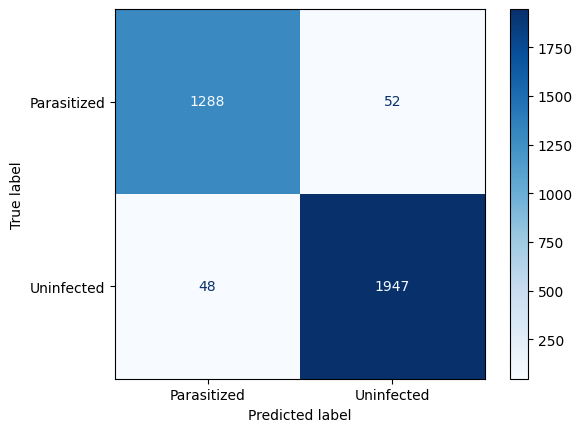

[[1288   52]
 [  48 1947]]


In [ ]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
print('Accuracy:', round((pred == y_test).mean(), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()
print(confusion_matrix(y_test, pred))

In [ ]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]          # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: {t:.3f}')

    # What that threshold gives on validation (where it was set)
    yv, sv = (y_val == pos), (p_val[:, pos] >= t)
    print(f'Validation recall at t: {(sv & yv).sum() / yv.sum():.3f} | '
          f'specificity: {(~sv & ~yv).sum() / (~yv).sum():.3f}')

    # Applied once to the test set
    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    ppv = tp / max(tp + fp, 1)
    prev = yt.mean()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'TP {tp}  FN {fn}  TN {tn}  FP {fp}')
    print(f'Sensitivity {sens:.3f}   Specificity {spec:.3f}   PPV {ppv:.3f}')
    print(f'Test-set prevalence: {prev:.3f}')

    # PPV = sens*prev / (sens*prev + (1-spec)*(1-prev))
    for pr in [prev, 0.05, 0.01]:
        v = sens * pr / (sens * pr + (1 - spec) * (1 - pr))
        print(f'PPV at prevalence {pr:.3f}: {v:.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.154
Validation recall at t: 0.951 | specificity: 0.934
Test AUC 0.994
TP 1316  FN 24  TN 1879  FP 116
Sensitivity 0.982   Specificity 0.942   PPV 0.919
Test-set prevalence: 0.402
PPV at prevalence 0.402: 0.919
PPV at prevalence 0.050: 0.471
PPV at prevalence 0.010: 0.146


## Part 5: test macro-F1 0.969; at threshold 0.154 sensitivity 0.982, specificity 0.942, PPV 0.919 on the test set, falling to 0.471 at 5% prevalence

**Numbers:**
- Test set (3,335 cells from 28 patients, used once): accuracy 0.970, macro-F1 0.969, test AUC 0.994.
- Per class at the default 0.5 cut-off: Parasitized precision 0.964, recall 0.961, F1 0.963 (1,340 images); Uninfected precision 0.974, recall 0.976, F1 0.975 (1,995 images). Confusion matrix: 1,288 parasitized found and 52 missed; 1,947 uninfected correct and 48 false alarms. The weakest class is Parasitized.
- Threshold: 0.154, chosen on the validation set for recall of at least 0.95 (validation recall 0.951, specificity 0.934), then applied once to the test set.
- Test result at 0.154: TP 1,316 | FN 24 | TN 1,879 | FP 116. Sensitivity = 1,316 / 1,340 = 0.982. Specificity = 1,879 / 1,995 = 0.942. PPV = 1,316 / 1,432 = 0.919. Test recall reached the 0.95 target.
- Test-set prevalence: 1,340 / 3,335 = 0.402.
- PPV = (sens x prev) / (sens x prev + (1 - spec) x (1 - prev)). The false-positive rate is 1 - spec = 116 / 1,995 = 0.0581. At 5% prevalence: (0.982 x 0.05) / (0.982 x 0.05 + 0.0581 x 0.95) = 0.0491 / (0.0491 + 0.0552) = 0.0491 / 0.1043 = 0.471. At 1% prevalence: (0.982 x 0.01) / (0.982 x 0.01 + 0.0581 x 0.99) = 0.0098 / (0.0098 + 0.0575) = 0.0098 / 0.0673 = 0.146.

**Decision:** Lowering the threshold from 0.5 to 0.154 cut missed infections from 52 to 24 but raised false alarms from 48 to 116, which is the right trade if a missed infection is the costly error. The PPV of 0.919 only holds because 40% of the test cells are parasitized: if I assume only 5% of cells in a real screening sample are parasitized, the same model and threshold give a PPV of 0.471, so more than half of the positive calls would be false alarms, and at 1% prevalence the PPV falls to 0.146. The sensitivity (0.982) and specificity (0.942) have not changed. What changed is that there are many more uninfected cells, so even a 5.8% false-positive rate produces a lot of false alarms compared with the few true positives. In practice a positive result should be confirmed by a microscopist and not treated as a diagnosis.

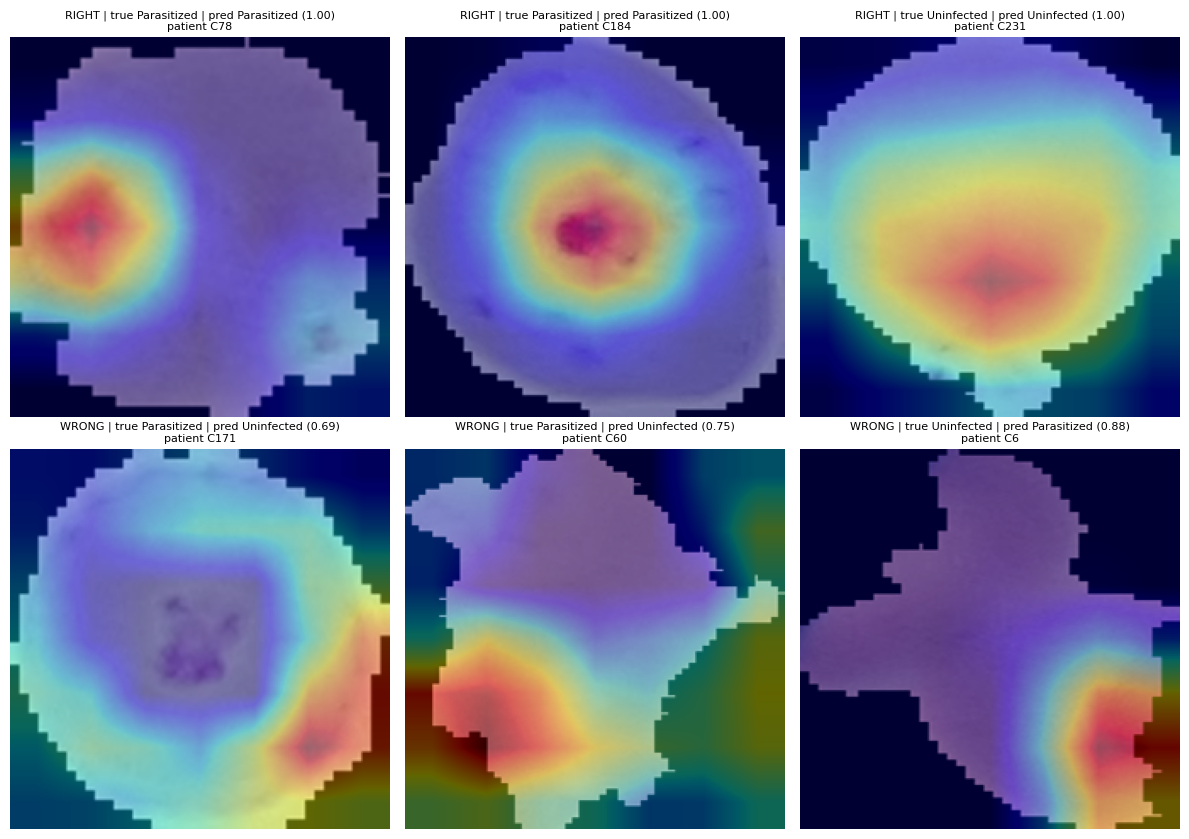

In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)        # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()       # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)

rng = np.random.RandomState(0)
def pick(mask, k):
    return rng.choice(np.where(mask)[0], k, replace=False).tolist()

P = classes.index(POSITIVE)
U = 1 - P
right = (pick((pred == y_test) & (y_test == P), 2)
         + pick((pred == y_test) & (y_test == U), 1))
wrong = (pick((pred != y_test) & (y_test == P), 2)
         + pick((pred != y_test) & (y_test == U), 1))

fig, axes = plt.subplots(2, 3, figsize=(12, 8.5))
for ax, i, tag in zip(axes.flat, right + wrong, ['RIGHT'] * 3 + ['WRONG'] * 3):
    x, y = test_ds[i]
    heat, c = cam(x)
    ax.imshow(test_ds.imgs[i].resize((IMG_SIZE,) * 2))
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'{tag} | true {classes[y]} | pred {classes[c]} ({p_test[i][c]:.2f})\n'
                 f'patient {test_df.iloc[i]["group"]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
rng2 = np.random.RandomState(1)
sel = rng2.choice(len(test_ds), 300, replace=False)
rows = []
for i in sel:
    x, y = test_ds[i]
    heat, c = cam(x)
    gray = np.array(test_ds.imgs[i].convert('L').resize((IMG_SIZE, IMG_SIZE)))
    bg = gray < 10                                   # black padding around the cell
    rows.append({'true': classes[y],
                 'bg_pixels': bg.mean(),             # share of the image that is background
                 'bg_attention': heat[bg].sum() / (heat.sum() + 1e-8)})
r = pd.DataFrame(rows)
print(r.groupby('true')[['bg_pixels', 'bg_attention']].mean().round(3))
print('Overall:', r[['bg_pixels', 'bg_attention']].mean().round(3).to_dict())

             bg_pixels  bg_attention
true                                
Parasitized      0.272         0.122
Uninfected       0.262         0.164
Overall: {'bg_pixels': 0.266, 'bg_attention': 0.146}


## Part 6: 6 heatmaps read; background gets 14.6% of the attention but 26.6% of the pixels; shortcut suspected (mild), not confirmed

**Numbers (background-attention check on 300 random test images):**
- Black background share of the image: 0.266 overall (Parasitized 0.272, Uninfected 0.262).
- Share of Grad-CAM attention on the background: 0.146 overall. Parasitized 0.122 (0.45 of its pixel share), Uninfected 0.164 (0.63 of its pixel share).

**One line per heatmap (layer4 Grad-CAM, 7 x 7 resolution upsampled):**
1. Correct, Parasitized (patient C78, 1.00): the strongest heat is at the left edge of the cell, where it meets the black padding, and I cannot see a clear parasite under it, so I cannot confirm this is legitimate evidence.
2. Correct, Parasitized (patient C184, 1.00): heat is centred on the dark purple spot in the middle of the cell, which is legitimate evidence.
3. Correct, Uninfected (patient C231, 1.00): broad heat over the lower middle of the cell body with no focus on the padding, so the model is looking at the plain cell interior, which is reasonable when there is no parasite to find.
4. Wrong, true Parasitized, predicted Uninfected (patient C171, 0.69): the dark purple cluster in the middle of the cell gets almost no heat, while the heat sits on the rim at the lower right, so the model looked at the edge and missed the parasite.
5. Wrong, true Parasitized, predicted Uninfected (patient C60, 0.75): heat is on the lower left of an irregularly shaped cell, near the edge, with no focus on a parasite, so the model looked at the outline and not at the evidence.
6. Wrong, true Uninfected, predicted Parasitized (patient C6, 0.88): heat is on the right edge of an oddly shaped cell, next to the padding, so the irregular outline, not a parasite, probably caused the false alarm.

**Decision:** The model mostly looks at the cell and not at the background. In both classes the background receives less attention than its share of the pixels (Parasitized 0.122 against 0.272, Uninfected 0.164 against 0.262), and heatmap 2 sits on a parasite spot. This argues against a strong background shortcut. I still rate the verdict “shortcut suspected (mild)”, for two reasons: Uninfected predictions put more attention on the background than Parasitized ones (0.164 against 0.122), and four of the six heatmaps (1, 4, 5 and 6) put their strongest heat on the cell edge, including all three errors, so the model may be using the cell outline as a clue. Six heatmaps and 300 attention scores are a small sample, so this is a suspicion and not a confirmed shortcut.

**Follow-up experiment:** For the test cells, black out a ring around the cell outline (for example the outer 10% of the cell) and re-score at the same threshold of 0.154. If sensitivity (0.982) or specificity (0.942) drops sharply, the model relies on the cell boundary and shape. I would then repeat with grayscale images to test the other suspect from Part 1, the stain colour.

In [ ]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

# Check the file loads and holds what we expect
ck = torch.load('/kaggle/working/week6_model.pt', map_location='cpu')
print(sorted(ck.keys()))
print(ck['classes'], ck['backbone'], ck['img_size'], ck['grayscale'])
print(f"File size: {os.path.getsize('/kaggle/working/week6_model.pt') / 1e6:.1f} MB")

Saved week6_model.pt
['backbone', 'classes', 'grayscale', 'img_size', 'state_dict']
['Parasitized', 'Uninfected'] resnet18 224 False
File size: 44.8 MB


## Part 7: ResNet-18 saved as week6_model.pt (44.8 MB) with 5 stored items, matching the model that scored test macro-F1 0.969

**Numbers:**
- File: `/kaggle/working/week6_model.pt`, size 44.8 MB.
- Keys stored (5): `backbone`, `classes`, `grayscale`, `img_size`, `state_dict`.
- Reload check: classes `['Parasitized', 'Uninfected']`, backbone `resnet18`, image size 224, `grayscale = False`.
- Weights: `state_dict` of the fine-tuned ResNet-18 (11,177,538 parameters), the best phase 2 epoch by validation macro-F1 (0.937, epoch 2).
- Not stored in the file: the decision threshold 0.154, which is recorded in the README.

**Decision:** I saved the model only after the test, threshold and Grad-CAM checks, so the file is the same model that the test results describe (macro-F1 0.969, sensitivity 0.982, specificity 0.942). The file holds the class order and preprocessing settings so that new images are prepared exactly as in training, and the 0.154 threshold must be applied separately, because the 0.5 default would miss more infections (52 compared with 24).

## Check Your Understanding: class weights 0.556 / 5.0, focal factor 0.04, PPV 0.269

### 1. Why does a random split of chest X-rays overestimate performance?

One patient usually has several X-rays with the same body, scanner and image quality. A random split puts some of them in training and some in the test set, so the model can recognise the patient or scanner instead of the disease. The test score then rewards memorised patients and is higher than it would be on new people.

### 2. Two classes have 900 and 100 training images. Compute both class weights with N / (K x n_c).

N = 900 + 100 = 1,000 and K = 2 classes.
- Class with 900 images: 1,000 / (2 x 900) = 1,000 / 1,800 = **0.556**
- Class with 100 images: 1,000 / (2 x 100) = 1,000 / 200 = **5.0**

The rare class counts 9 times more per image (5.0 / 0.556 = 9), which matches the 900 : 100 ratio, so both classes contribute equally to the loss.

### 3. With focal loss and gamma = 2, by what factor is an example with p_t = 0.8 down-weighted?

Focal loss multiplies the usual cross-entropy by (1 - p_t)^gamma.

(1 - 0.8)^2 = 0.2^2 = **0.04**

The example keeps 4% of its normal loss (25 times smaller), so examples the model already gets right barely affect training and the hard examples dominate.

### 4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.

PPV = (sens x prev) / (sens x prev + (1 - spec) x (1 - prev))
- True-positive part: 0.90 x 0.02 = 0.018
- False-positive part: (1 - 0.95) x (1 - 0.02) = 0.05 x 0.98 = 0.049
- PPV = 0.018 / (0.018 + 0.049) = 0.018 / 0.067 = **0.269**

Only about 27% of positive calls are true positives, because the condition is rare and the many healthy people produce more false alarms than the few sick people produce true positives.

### 5. When is macro-F1 a better selection metric than weighted F1?

Macro-F1 is better when the classes are imbalanced and the rare class matters most, because it averages the per-class F1 scores equally, while weighted F1 lets the large class dominate. With 900 and 100 images, a model that always predicts the large class has F1 = 0.947 for it and 0 for the small class. Its macro-F1 is (0.947 + 0) / 2 = **0.474**, but its weighted F1 is 0.9 x 0.947 = **0.852**, which hides that it finds no rare cases.

### 6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?

This is a shortcut: the model is using a mark that identifies the hospital and not the lungs, so I would not deploy it. I would first crop or cover the label on the test images and re-score, because a large drop confirms the shortcut. Then I would remove the label from every image, retrain, check Grad-CAM again, and test on images from a different hospital.